<a href="https://colab.research.google.com/github/MAI-AIIU/deep-learning/blob/main/src/fourth-week/linear-regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Metadata
**Name**  
> Naveed Ahmad Hematmal

**Assignment**    

> Linear Regression from scratch

# Linear Regression Implementation from Scratch
:label:`sec_linear_scratch`

We are now ready to work through
a fully functioning implementation
of linear regression.
In this section,
(**we will implement the entire method from scratch,
including (i) the model; (ii) the loss function;
(iii) a minibatch stochastic gradient descent optimizer;
and (iv) the training function
that stitches all of these pieces together.**)
Finally, we will run our synthetic data generator
from :numref:`sec_synthetic-regression-data`
and apply our model
on the resulting dataset.
While modern deep learning frameworks
can automate nearly all of this work,
implementing things from scratch is the only way
to make sure that you really know what you are doing.
Moreover, when it is time to customize models,
defining our own layers or loss functions,
understanding how things work under the hood will prove handy.
In this section, we will rely only
on tensors and automatic differentiation.
Later, we will introduce a more concise implementation,
taking advantage of the bells and whistles of deep learning frameworks
while retaining the structure of what follows below.


In [1]:
%matplotlib inline
import math
import torch
import random
import numpy as np
import matplotlib.pyplot as plt
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset

In [2]:
# Reproducibility
RND = 42
random.seed(RND)
np.random.seed(RND)
torch.manual_seed(RND)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device:", device)

Device: cuda


In [3]:
def add_to_class(cls):
    """Decorator that adds the decorated function as a method to `cls`."""
    def decorator(func):
        setattr(cls, func.__name__, func)
        return func
    return decorator

Synthetic regression dataset (PyTorch Dataset + helper)

In [4]:
# Synthetic data helper and dataloaders
def make_synthetic_regression(w, b, num_examples=1000, noise_std=0.1, batch_size=32, val_frac=0.2):
    w = torch.tensor(w, dtype=torch.float32).reshape(-1)
    b = float(b)
    n, d = num_examples, w.numel()
    X = torch.randn(n, d)
    y = X.matmul(w) + b + noise_std * torch.randn(n)
    n_val = int(n * val_frac)
    X_train, y_train = X[:-n_val], y[:-n_val]
    X_val, y_val = X[-n_val:], y[-n_val:]
    train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=batch_size, shuffle=False)
    # return true params for later comparison
    return train_loader, val_loader, w, b

## Defining the Model

[**Before we can begin optimizing our model's parameters**] by minibatch SGD,
(**we need to have some parameters in the first place.**)
In the following we initialize weights by drawing
random numbers from a normal distribution with mean 0
and a standard deviation of 0.01.
The magic number 0.01 often works well in practice,
but you can specify a different value
through the argument `sigma`.
Moreover we set the bias to 0.
Note that for object-oriented design
we add the code to the `__init__` method of a subclass of `d2l.Module` (introduced in :numref:`subsec_oo-design-models`).


In [5]:
# Model: manual parameters with nn.Module wrapper
class LinearRegressionScratch(nn.Module):
    def __init__(self, num_inputs, sigma=0.01):
        super().__init__()
        # w shape (d,1) so X @ w -> (batch,1). We'll squeeze to (batch,)
        self.w = nn.Parameter(torch.randn(num_inputs, 1) * sigma)
        self.b = nn.Parameter(torch.zeros(1))

Next we must [**define our model,
relating its input and parameters to its output.**]
Using the same notation as :eqref:`eq_linreg-y-vec`
for our linear model we simply take the matrix--vector product
of the input features $\mathbf{X}$
and the model weights $\mathbf{w}$,
and add the offset $b$ to each example.
The product $\mathbf{Xw}$ is a vector and $b$ is a scalar.
Because of the broadcasting mechanism
(see :numref:`subsec_broadcasting`),
when we add a vector and a scalar,
the scalar is added to each component of the vector.
The resulting `forward` method
is registered in the `LinearRegressionScratch` class
via `add_to_class` (introduced in :numref:`oo-design-utilities`).


In [6]:
@add_to_class(LinearRegressionScratch)
def forward(self, X):
        # X: (batch, d)
        #return X.matmul(self.w).squeeze(-1) + self.b
        return torch.matmul(X, self.w) + self.b

## Defining the Loss Function

Since [**updating our model requires taking
the gradient of our loss function,**]
we ought to (**define the loss function first.**)
Here we use the squared loss function
in :eqref:`eq_mse`.
In the implementation, we need to transform the true value `y`
into the predicted value's shape `y_hat`.
The result returned by the following method
will also have the same shape as `y_hat`.
We also return the averaged loss value
among all examples in the minibatch.


In [7]:
# MSE with 1/2 factor (returns averaged loss over batch)
def mse_loss_half(y_hat, y):
    # y_hat and y are (batch,)
    return ((y_hat - y) ** 2 / 2).mean()

# Quick sanity check using random tensors
# if __name__ == "__main__":
#     y_hat = torch.tensor([1.0, 2.0, 3.0])
#     y = torch.tensor([1.1, 1.9, 2.8])
#     print("Sanity loss:", mse_loss_half(y_hat, y).item())

## Defining the Optimization Algorithm

As discussed in :numref:`sec_linear_regression`,
linear regression has a closed-form solution.
However, our goal here is to illustrate
how to train more general neural networks,
and that requires that we teach you
how to use minibatch SGD.
Hence we will take this opportunity
to introduce your first working example of SGD.
At each step, using a minibatch
randomly drawn from our dataset,
we estimate the gradient of the loss
with respect to the parameters.
Next, we update the parameters
in the direction that may reduce the loss.

The following code applies the update,
given a set of parameters, a learning rate `lr`.
Since our loss is computed as an average over the minibatch,
we do not need to adjust the learning rate against the batch size.
In later chapters we will investigate
how learning rates should be adjusted
for very large minibatches as they arise
in distributed large-scale learning.
For now, we can ignore this dependency.


We define our `SGD` class,
a subclass of `d2l.HyperParameters` (introduced in :numref:`oo-design-utilities`),
to have a similar API
as the built-in SGD optimizer.
We update the parameters in the `step` method.
The `zero_grad` method sets all gradients to 0,
which must be run before a backpropagation step.


In [8]:
# Option A: use built-in torch.optim.SGD (recommended)
def make_torch_sgd(model, lr):
    return torch.optim.SGD(model.parameters(), lr=lr)

# Option B: minimal custom SGD (demonstrative)
class SimpleSGD:
    def __init__(self, params, lr):
        self.params = list(params)
        self.lr = lr
    def zero_grad(self):
        for p in self.params:
            if p.grad is not None:
                p.grad.zero_()
    def step(self):
        with torch.no_grad():
            for p in self.params:
                if p.grad is None:
                    continue
                p.data -= self.lr * p.grad

## Training

Now that we have all of the parts in place
(parameters, loss function, model, and optimizer),
we are ready to [**implement the main training loop.**]
It is crucial that you understand this code fully
since you will employ similar training loops
for every other deep learning model
covered in this book.
In each *epoch*, we iterate through
the entire training dataset,
passing once through every example
(assuming that the number of examples
is divisible by the batch size).
In each *iteration*, we grab a minibatch of training examples,
and compute its loss through the model's `training_step` method.
Then we compute the gradients with respect to each parameter.
Finally, we will call the optimization algorithm
to update the model parameters.
In summary, we will execute the following loop:

* Initialize parameters $(\mathbf{w}, b)$
* Repeat until done
    * Compute gradient $\mathbf{g} \leftarrow \partial_{(\mathbf{w},b)} \frac{1}{|\mathcal{B}|} \sum_{i \in \mathcal{B}} l(\mathbf{x}^{(i)}, y^{(i)}, \mathbf{w}, b)$
    * Update parameters $(\mathbf{w}, b) \leftarrow (\mathbf{w}, b) - \eta \mathbf{g}$

Recall that the synthetic regression dataset
that we generated in :numref:``sec_synthetic-regression-data``
does not provide a validation dataset.
In most cases, however,
we will want a validation dataset
to measure our model quality.
Here we pass the validation dataloader
once in each epoch to measure the model performance.
Following our object-oriented design,
the `prepare_batch` and `fit_epoch` methods
are registered in the `d2l.Trainer` class
(introduced in :numref:`oo-design-training`).


We are almost ready to train the model,
but first we need some training data.
Here we use the `SyntheticRegressionData` class
and pass in some ground truth parameters.
Then we train our model with
the learning rate `lr=0.03`
and set `max_epochs=3`.
Note that in general, both the number of epochs
and the learning rate are hyperparameters.
In general, setting hyperparameters is tricky
and we will usually want to use a three-way split,
one set for training,
a second for hyperparameter selection,
and the third reserved for the final evaluation.
We elide these details for now but will revise them
later.


In [29]:
# Example: create dataloaders (used later in training)
train_loader, val_loader, true_w, true_b = make_synthetic_regression(
    w=[2.0, -3.4], b=4.2, num_examples=1000, noise_std=0.1, batch_size=32, val_frac=0.2
)

# based on exercise 1, we are changing w to [0, 0] to check if still algorithm works or not.
# train_loader, val_loader, true_w, true_b = make_synthetic_regression(
#     w=[0, 0], b=4.2, num_examples=1000, noise_std=0.1, batch_size=32, val_frac=0.2
# )

# changing batch_size to see what happens to data_iter
# train_loader, val_loader, true_w, true_b = make_synthetic_regression(
#     w=[0, 0], b=4.2, num_examples=1000, noise_std=0.1, batch_size=11, val_frac=0.2
# )

print("True w:", true_w, "True b:", true_b)

True w: tensor([ 2.0000, -3.4000]) True b: 4.2


Epoch 1/3 — train_loss: 9.893224 — val_loss: 7.712069
Epoch 2/3 — train_loss: 7.937838 — val_loss: 7.432209
Epoch 3/3 — train_loss: 7.898133 — val_loss: 7.422467
Training finished in 0.27s


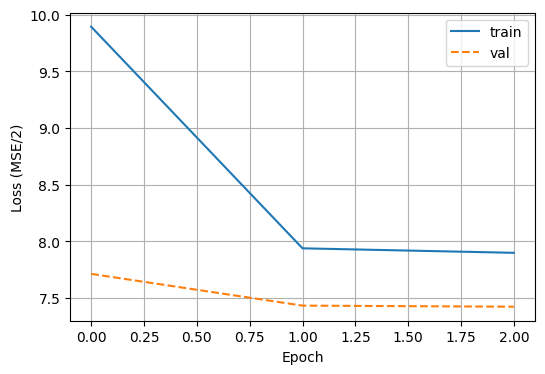

true w: [ 2.  -3.4]
learned w: [ 0.13789882 -0.36164263]
error in estimating w: [ 1.8621012 -3.0383575]
true b: 4.2
learned b: 4.004150867462158
error in estimating b: 0.19584913253784197


In [30]:
import time

# Hyperparameters
lr = 0.03 # we change learning rate to check the loss function
max_epochs = 3 # we change max epochs to check the accuracy
use_custom_optimizer = False  # set True to use SimpleSGD

# Prepare model, optimizer, device
model = LinearRegressionScratch(num_inputs=true_w.numel(), sigma=0.01).to(device)

# we change sigma (variance in the model from 0.01 to 1000) and see the difference.
# model = LinearRegressionScratch(num_inputs=true_w.numel(), sigma=1000).to(device)

optimizer = SimpleSGD(model.parameters(), lr) if use_custom_optimizer else make_torch_sgd(model, lr)

train_losses, val_losses = [], []

start_time = time.time()
for epoch in range(1, max_epochs + 1):
    # Training
    model.train()
    running_loss = 0.0
    nb = 0
    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # forward
        y_hat = model(X_batch)
        loss = mse_loss_half(y_hat, y_batch)

        # backward
        optimizer.zero_grad() if not use_custom_optimizer else optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        nb += 1
    train_loss = running_loss / max(1, nb)
    train_losses.append(train_loss)

    # Validation
    model.eval()
    val_running = 0.0
    vb = 0
    with torch.no_grad():
        for Xv, yv in val_loader:
            Xv = Xv.to(device)
            yv = yv.to(device)
            yv_hat = model(Xv)
            vloss = mse_loss_half(yv_hat, yv)
            val_running += vloss.item()
            vb += 1
    val_loss = val_running / max(1, vb)
    val_losses.append(val_loss)

    print(f"Epoch {epoch}/{max_epochs} — train_loss: {train_loss:.6f} — val_loss: {val_loss:.6f}")

elapsed = time.time() - start_time
print(f"Training finished in {elapsed:.2f}s")

# Plot losses
plt.figure(figsize=(6,4))
plt.plot(train_losses, label='train')
plt.plot(val_losses, label='val', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE/2)')
plt.legend()
plt.grid(True)
plt.show()

# Compare learned vs true parameters
with torch.no_grad():
    learned_w = model.w.reshape(-1).cpu()
    learned_b = model.b.cpu().item()
    print("true w:", true_w.numpy())
    print("learned w:", learned_w.numpy())
    print("error in estimating w:", (true_w - learned_w).numpy())
    print("true b:", true_b)
    print("learned b:", learned_b)
    print("error in estimating b:", true_b - learned_b)

## Exercises

1. What would happen if we were to initialize the weights to zero. Would the algorithm still work? What if we
   initialized the parameters with variance $1000$ rather than $0.01$?
1. Experiment using different learning rates to find out how quickly the loss function value drops. Can you reduce the
   error by increasing the number of epochs of training?
1. If the number of examples cannot be divided by the batch size, what happens to `data_iter` at the end of an epoch?
1


## Solutions
1. Initializing weights to zero changes the estimation of w, and also error in estimating w. but it doesn't change bias too much. and changing variance (sigma) value from 0.01 to 1000 changed first weight by a very big factor and second weight by respectively small factor
1. changing learning rate to a bigger number decreases loss quickly, but increasing epochs doesn't really help in this example, at first three epochs loss was decreased and after that it was decreased by a fraction of number no matter how many more epochs we add.
1. if dividing examples by batch_size came with remainder, nothing breaks, nothing happens, only the last batch will have the remainder or less amount of examples. for example if 100 is examples, and 21 is batch_size. the first four batch will have 20 examples total 80, the last 16 examples will be on 5th batch. that's how pytorch's DataLoader behave.